## 1. Load the CSV Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

file_path = '/content/drive/MyDrive/sem3/mini project - Bipolar Disorder/bipolar-raw-dataset.csv'
df = pd.read_csv(file_path)

display(df.head())

,Record ID,Gender:,Marital Status:,No of biological children:,Date of Assessment of File/ Interview:,Date of Registration:,Date of Birth:,Age,Birth City:,Birth State,...,Criteria B Score,Total Score,Kindly rate your social life and friendships before becoming ill,Kindly rate your self-Care and activities of daily living over the last 5 years,"In the last 5 years, were you going to-",Kindly rate your occupational functioning in the last 5 years.,Are you currently married or in a long-term relationship?,Kindly rate any impairment in capacity for intimate relationship in the last five years,"Any additional information pertaining to self care, work and social adjustment-",Genotyped?
0,2,Male,Married,2.0,2025-12-22,1996-01-17,1976-01-01,50.0,Kanakapura,Karnataka,...,2.0,7.0,3.0,1.0,Worked outside home,1.0,Yes,1.0,NaN,Yes
1,3,Male,Married,0.0,2023-02-07,1995-04-04,1956-01-01,67.1,BANGALORE,KARNATAKA,...,1.0,9.0,NaN,2.0,NaN,2.0,No,1.0,NaN,Yes
2,4,Male,Married,NaN,2023-02-13,1995-04-27,1975-01-01,48.1,NAMAKKAL,TAMIN NADU,...,0.0,10.0,NaN,4.0,Worked outside home,4.0,Yes,3.0,NaN,Yes
3,5,Male,Married,NaN,2023-02-14,1995-03-22,1965-01-01,58.1,MYSORE,KARNATAKA,...,2.0,8.0,NaN,4.0,NaN,NaN,Yes,3.0,NaN,Yes
4,6,Female,Married,1.0,2023-02-15,1995-04-07,1974-01-01,49.1,BANGALORE,KARNATAKA,...,4.0,6.0,3.0,5.0,NaN,4.0,Yes,3.0,NaN,Yes


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 367 entries, 0 to 366
Columns: 430 entries, Record ID to Genotyped?
dtypes: float64(148), int64(1), object(281)
memory usage: 1.2+ MB
None


## 2. Clean dataset column names

remove special characters like '(', ':', '=' etc...

transform " "(space) into underscores

In [ ]:
import re

def clean_column_names(dataframe: pd.DataFrame)-> pd.DataFrame:
  '''
  This function takes dataframe as input and return the dataframe with cleaned column names
  '''
  cleaned_cols = []
  for col in df.columns:
    c = col.strip().lower()
    c = re.sub(r'[^\w\s]', '', c)
    c = re.sub(r'\s+', '_', c)
    cleaned_cols.append(c)
  dataframe.columns = cleaned_cols # replacing the actual dataframe column names with new cleaned column names
  return dataframe

#call the function
df = clean_column_names(df)

print("Cleaned column count = ", len(df.columns))
print(df.columns.tolist())

Cleaned column count =  430
['record_id', 'gender', 'marital_status', 'no_of_biological_children', 'date_of_assessment_of_file_interview', 'date_of_registration', 'date_of_birth', 'age', 'birth_city', 'birth_state', 'birth_country', 'current_city', 'current_state', 'current_country', 'background', 'religion', 'income', 'education', 'years_of_education', 'occupation', 'occupation_details', 'detailed_workup', 'full_diagnosis', 'family_history_of_psychiatric_illness_in_first_degree_relatives_choice1_schizophreniapsychosis', 'family_history_of_psychiatric_illness_in_first_degree_relatives_choice2_bpad', 'family_history_of_psychiatric_illness_in_first_degree_relatives_choice3_rdd', 'family_history_of_psychiatric_illness_in_first_degree_relatives_choice4_substance_dependence', 'family_history_of_psychiatric_illness_in_first_degree_relatives_choice5_anxiety_disorders', 'fdr_scz_count', 'fdr_bpad_count', 'fdr_rdd_count', 'fdr_sud_count', 'fdr_anx_count', 'total_number_of_affected_first_degree_

## 3. Feature extraction

extracting core features from the 430 available features in the raw dataset


In [ ]:
selected_features = [
    # Demographics & Context
    'age', 'gender', 'marital_status', 'education',

    # Trajectory & Episode Metrics
    'age_at_onset_of_illness_first_episode',
    'total_number_of_episodes',
    'total_duration_of_illness_in_months',
    'total_duration_of_all_episodes_in_months',
    'total_duration_of_hypomanic_episodes_in_months',
    'total_number_of_manic_episodes',
    'total_number_of_hypomanic_episodes',
    'total_number_of_mixed_episodes',
    'total_number_of_depressive_episodes',
    'lifetime_history_of_rapid_cycling',
    'percentage_of_time_with_symptoms',
    'interepisodic_remission',
    'maximum_interepisodic_duration_in_months',
    'rate_time_spent_euthymic_since_onset',
    'rate_prominence_of_mixed_episodes',
    'in_first_five_years_of_illness_after_onset_rate_the_amount_of_time_spent_primarily_in_manic_vs_depressive_symptoms_on_5point_scale',
    'in_more_recent_years_of_illness_rate_the_amount_of_time_spent_primarily_in_manic_vs_depressive_symptoms_on_5point_scale',

    # Manic Symptom Domain
    'has_there_ever_been_a_manic_episode',
    'persistent_elevated_mood', 'persistent_irritability', 'dec_need_for_sleep',
    'inc_speech_rate_and_amount', 'foiracing_thoughts', 'distractibility',
    'inc_pma', 'grandiosity', 'overfamiliarity', 'increased_sexual_interest',
    'agitation', 'high_risk_behaviours',

    # Depressive Symptom Domain
    'has_there_ever_been_a_depressive_episode',
    'per_low_mood', 'emptiness', 'anh', 'ef', 'guilt', 'worthless',
    'poor_conc', 'self_harm_ideation', 'suicidal_attempt',

    # Psychotic & Negative Symptom Domain
    'has_there_ever_been_psychotic_symptoms', 'psy_symp',
    'del_ref', 'del_per', 'del_gran', 'del_sin', 'del_ctrl', 'del_soma',
    'thought_phen', 'ah', 'vh', 'disorg_speech', 'disorg_behaviour',
    'catatonia', 'avolition', 'blunted_affect', 'rate_negative_symptoms',

    # Severity & Functioning
    'insightinterepisode', 'social_dysfunction', 'relationship_dysfunction',
    'occupational_dysfunction', 'kindly_rate_your_occupational_functioning_in_the_last_5_years',
    'hospitalized', 'number_of_ip_care_recieved', 'a_criterion_score', 'criteria_b_score', 'total_score',

    # Comorbidities
    'psychiatric_comorbidity_choiceanxiety_disorders',
    'psychiatric_comorbidity_choicepersonality_disorders',
    'psychiatric_comorbidity_choiceocrds',
    'psychiatric_comorbidity_choicetrauma_and_related_disorders',
    'psychiatric_comorbidity_choiceadhd',
    'psychiatric_comorbidity_choiceeating_disorders',
    'comorbid_substance_use_disorder_choicetobacco_dependence',
    'comorbid_substance_use_disorder_choicealcohol_dependence',
    'comorbid_substance_use_disorder_choicecannabis_dependence'
]

#extend the 80 features to include an 8 more features from nimhan's suggested 39 features
selected_features.extend(['ever_been_treated_with_antipsychotics', 'rate_response_to_lithium_treatment', 'ect_recieved', 'psychotic_symptoms', 'index_episode_episode_at_presentation_to_nimhans', 'ever_been_treated_with_anticonvulsants', 'ever_been_treated_with_lithium', 'antipsychotic'])


In [ ]:
selected_features.remove('psychotic_symptoms')
#reason: https://claude.ai/share/2718890b-ad0a-4715-9afe-554346f5d91b
#it was found psychotic_symptoms is noisy and unwanted

In [ ]:
df_subset = df[selected_features].copy()
print("Actual columns length in selected features list: ", len(selected_features))
print("Selected Subset Shape: ", df_subset.shape)

Actual columns length in selected features list:  87
Selected Subset Shape:  (367, 87)


In [ ]:
rename_dict = {
    'age_at_onset_of_illness_first_episode': 'age_onset',
    'has_there_ever_been_a_manic_episode': 'ever_manic',
    'has_there_ever_been_a_depressive_episode': 'ever_depressive',
    'has_there_ever_been_psychotic_symptoms': 'ever_psychotic',
    'psy_symp': 'psychotic_symptoms_index_episode',
    'foiracing_thoughts': 'racing_thoughts',
    'inc_pma': 'pma_mania',
    'per_low_mood': 'low_mood',
    'anh': 'anhedonia',
    'ef': 'executive_dysfunction',
    'poor_conc': 'poor_concentration',
    'kindly_rate_your_occupational_functioning_in_the_last_5_years': 'occupational_func_5yr',
    'in_first_five_years_of_illness_after_onset_rate_the_amount_of_time_spent_primarily_in_manic_vs_depressive_symptoms_on_5point_scale': 'mania_vs_dep_first5yr',
    'in_more_recent_years_of_illness_rate_the_amount_of_time_spent_primarily_in_manic_vs_depressive_symptoms_on_5point_scale': 'mania_vs_dep_recent',
    'psychiatric_comorbidity_choiceanxiety_disorders': 'comorbid_anxiety',
    'psychiatric_comorbidity_choicepersonality_disorders': 'comorbid_personality',
    'psychiatric_comorbidity_choiceocrds': 'comorbid_ocd',
    'psychiatric_comorbidity_choicetrauma_and_related_disorders': 'comorbid_trauma',
    'psychiatric_comorbidity_choiceadhd': 'comorbid_adhd',
    'psychiatric_comorbidity_choiceeating_disorders': 'comorbid_eating',
    'comorbid_substance_use_disorder_choicetobacco_dependence': 'substance_tobacco',
    'comorbid_substance_use_disorder_choicealcohol_dependence': 'substance_alcohol',
    'comorbid_substance_use_disorder_choicecannabis_dependence': 'substance_cannabis'
}

df_subset = df_subset.rename(columns=rename_dict)
df_subset.head()

,age,gender,marital_status,education,age_onset,total_number_of_episodes,total_duration_of_illness_in_months,total_duration_of_all_episodes_in_months,total_duration_of_hypomanic_episodes_in_months,total_number_of_manic_episodes,...,substance_tobacco,substance_alcohol,substance_cannabis,ever_been_treated_with_antipsychotics,rate_response_to_lithium_treatment,ect_recieved,index_episode_episode_at_presentation_to_nimhans,ever_been_treated_with_anticonvulsants,ever_been_treated_with_lithium,antipsychotic
0,50.0,Male,Married,8th std,17.0,11.0,395.6,41.5,2,7.0,...,Checked,Unchecked,Unchecked,Yes,8,No,Mania without psychotic symptoms,Yes,Yes,Chlorpromazine
1,67.1,Male,Married,NaN,38.6,6.0,342.2,13.0,0,4.0,...,Unchecked,Unchecked,Unchecked,Yes,8,No,Mania with psychotic symptoms,No,Yes,RESPERIDON
2,48.1,Male,Married,"MSC, B.ED",20.3,7.0,333.6,7.0,0,6.0,...,Unchecked,Unchecked,Unchecked,Yes,10=robust,Yes,Mania with psychotic symptoms,No,Yes,CPZ
3,58.1,Male,Married,NOT LITERATE,30.2,6.0,334.7,7.0,0,4.0,...,Unchecked,Unchecked,Unchecked,Yes,9,No,Mania with psychotic symptoms,No,Yes,CPZ
4,49.1,Female,Married,NaN,21.2,11.0,335.2,16.0,0,9.0,...,Unchecked,Unchecked,Unchecked,Yes,9,Yes,Mania with psychotic symptoms,No,Yes,CPZ


## 4. Data cleaning

- analyse values of each feature
- handle missing values

In [ ]:
display(df_subset.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 367 entries, 0 to 366
Data columns (total 87 columns):
 #   Column                                            Non-Null Count  Dtype  
---  ------                                            --------------  -----  
 0   age                                               297 non-null    float64
 1   gender                                            358 non-null    object 
 2   marital_status                                    343 non-null    object 
 3   education                                         290 non-null    object 
 4   age_onset                                         292 non-null    float64
 5   total_number_of_episodes                          305 non-null    float64
 6   total_duration_of_illness_in_months               277 non-null    float64
 7   total_duration_of_all_episodes_in_months          304 non-null    float64
 8   total_duration_of_hypomanic_episodes_in_months    277 non-null    object 
 9   total_number_of_manic

None

### 4.1 Understand the Structure & Audit Quality

- Dimensionality
- Data Type Inspection
- Missing Values
- Duplicate Rows


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

missing_count = df_subset.isnull().sum()
missing_percent = (missing_count/len(df_subset))*100

dictionary = dict(missing_percent)
below20 = [key for key,value in dictionary.items() if value < 20]
btw20and40 = [key for key,value in dictionary.items() if value >= 20 and value < 40]
above40 = [key for key,value in dictionary.items() if value >= 40]

print(f"Missing Count below 20% {below20} \n Misssing count = {len(below20)}")
print(f"Missing Count between 20% and 40% {btw20and40} \n Misssing count = {len(btw20and40)}")
print(f"Missing Count above 40% {above40} \n Misssing count = {len(above40)}")



Missing Count below 20% ['age', 'gender', 'marital_status', 'total_number_of_episodes', 'total_duration_of_all_episodes_in_months', 'total_number_of_manic_episodes', 'lifetime_history_of_rapid_cycling', 'rate_time_spent_euthymic_since_onset', 'rate_prominence_of_mixed_episodes', 'mania_vs_dep_first5yr', 'mania_vs_dep_recent', 'persistent_elevated_mood', 'persistent_irritability', 'dec_need_for_sleep', 'inc_speech_rate_and_amount', 'racing_thoughts', 'distractibility', 'pma_mania', 'grandiosity', 'overfamiliarity', 'increased_sexual_interest', 'agitation', 'social_dysfunction', 'relationship_dysfunction', 'occupational_dysfunction', 'hospitalized', 'comorbid_anxiety', 'comorbid_personality', 'comorbid_ocd', 'comorbid_trauma', 'comorbid_adhd', 'comorbid_eating', 'substance_tobacco', 'substance_alcohol', 'substance_cannabis', 'ect_recieved', 'index_episode_episode_at_presentation_to_nimhans', 'ever_been_treated_with_lithium'] 
 Misssing count = 38
Missing Count between 20% and 40% ['educa

In [ ]:
# Numerical and categorical columns overall
numerical_cols = df_subset.select_dtypes(include=['int64', 'float64']).columns.to_list()
categorical_cols = df_subset.select_dtypes(include=['object', 'category']).columns.to_list()

print(f"Numerical columns count: {len(numerical_cols)}")
print(f"Categorical columns count: {len(categorical_cols)}")
print()

# Now filter by missing thresholds
num_cols_below20 = [col for col in below20 if col in numerical_cols]
cat_cols_below20 = [col for col in below20 if col in categorical_cols]

num_cols_btw20and40 = [col for col in btw20and40 if col in numerical_cols]
cat_cols_btw20and40 = [col for col in btw20and40 if col in categorical_cols]

num_cols_above40 = [col for col in above40 if col in numerical_cols]
cat_cols_above40 = [col for col in above40 if col in categorical_cols]

# Print results
print(f"Numerical cols with missing count below 20% = {num_cols_below20}")
print(f"Categorical cols with missing count below 20% = {cat_cols_below20}")
print()

print(f"Numerical cols with missing between 20% and 40% = {num_cols_btw20and40}")
print(f"Categorical cols with missing count between 20% and 40% = {cat_cols_btw20and40}")
print()

print(f"Numerical cols with missing count above 40% = {num_cols_above40}")
print(f"Categorical cols with missing count above 40% = {cat_cols_above40}")


Numerical columns count: 21
Categorical columns count: 66

Numerical cols with missing count below 20% = ['age', 'total_number_of_episodes', 'total_duration_of_all_episodes_in_months', 'total_number_of_manic_episodes', 'rate_time_spent_euthymic_since_onset', 'rate_prominence_of_mixed_episodes', 'mania_vs_dep_first5yr', 'mania_vs_dep_recent']
Categorical cols with missing count below 20% = ['gender', 'marital_status', 'lifetime_history_of_rapid_cycling', 'persistent_elevated_mood', 'persistent_irritability', 'dec_need_for_sleep', 'inc_speech_rate_and_amount', 'racing_thoughts', 'distractibility', 'pma_mania', 'grandiosity', 'overfamiliarity', 'increased_sexual_interest', 'agitation', 'social_dysfunction', 'relationship_dysfunction', 'occupational_dysfunction', 'hospitalized', 'comorbid_anxiety', 'comorbid_personality', 'comorbid_ocd', 'comorbid_trauma', 'comorbid_adhd', 'comorbid_eating', 'substance_tobacco', 'substance_alcohol', 'substance_cannabis', 'ect_recieved', 'index_episode_epis

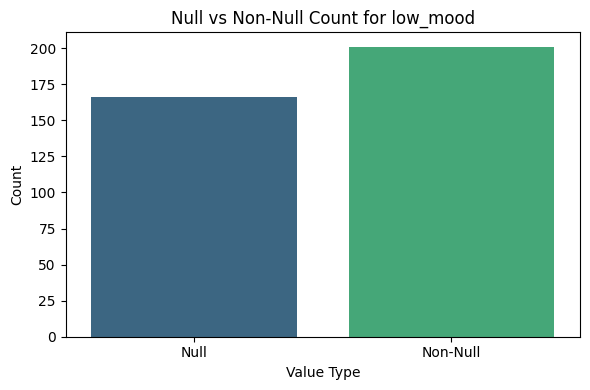

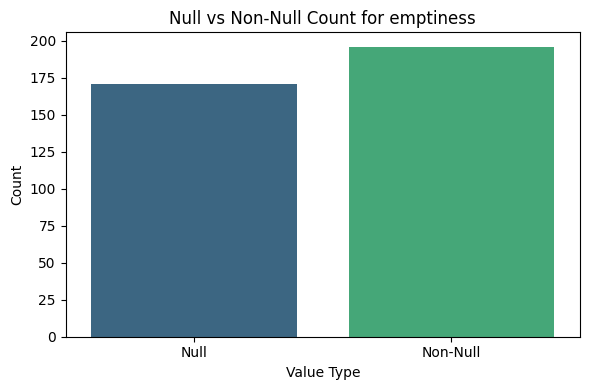

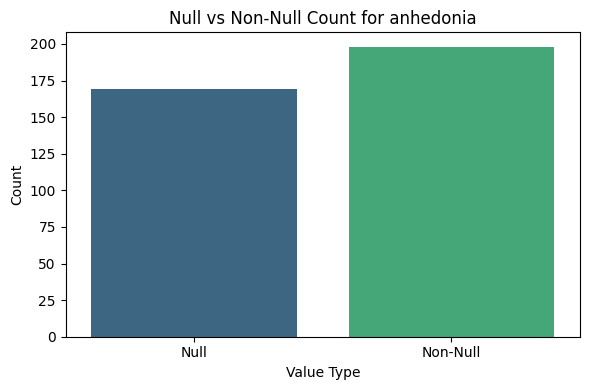

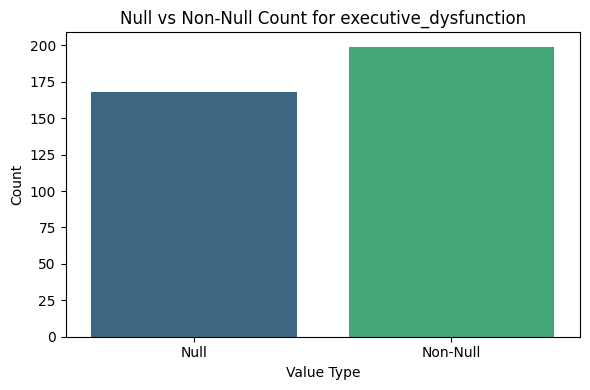

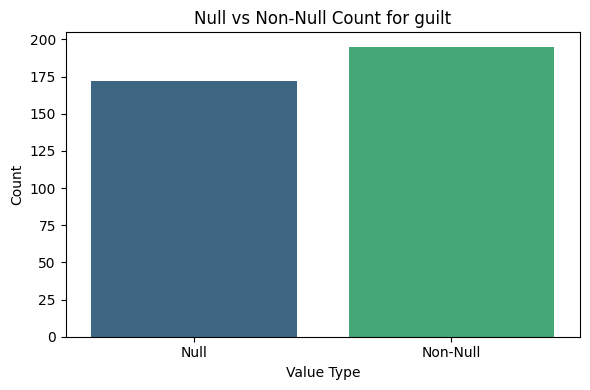

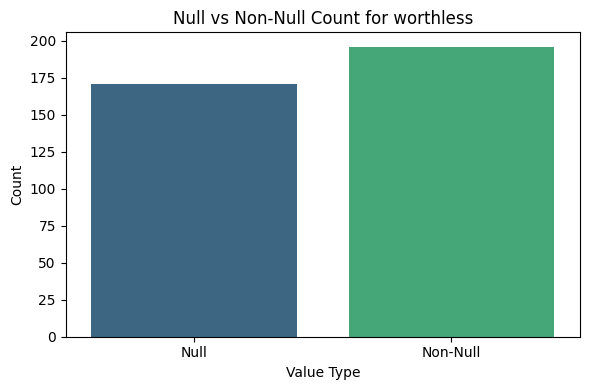

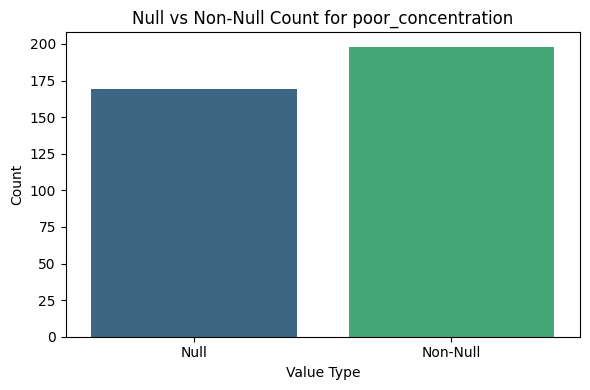

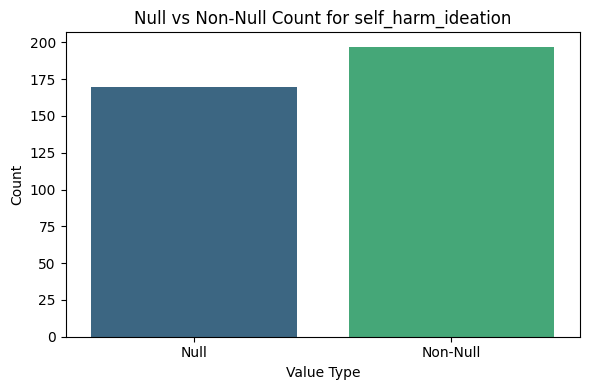

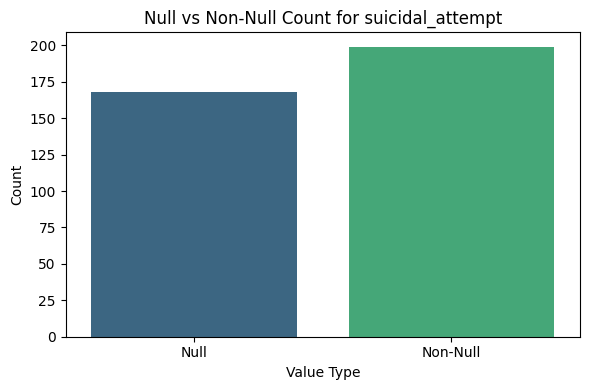

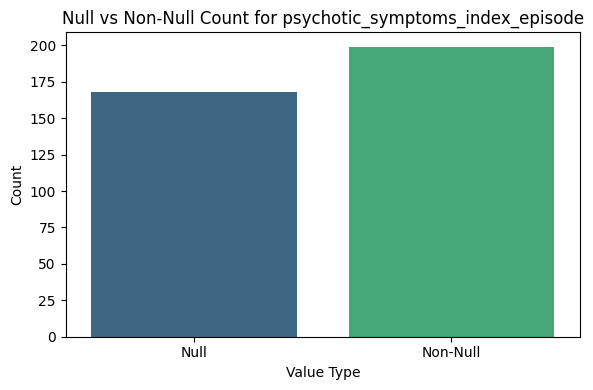

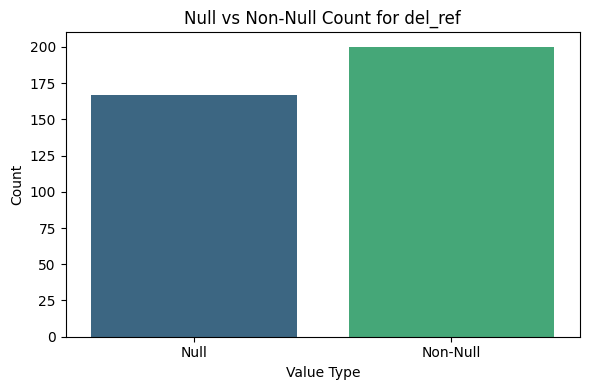

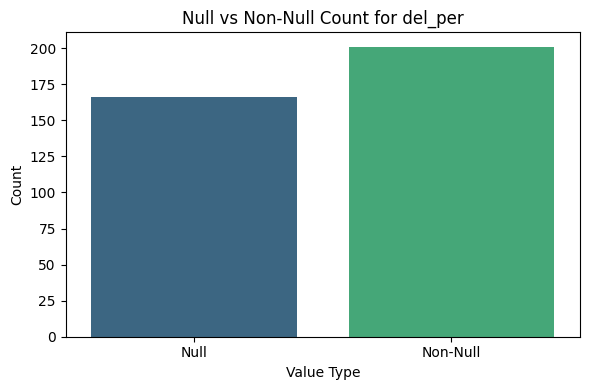

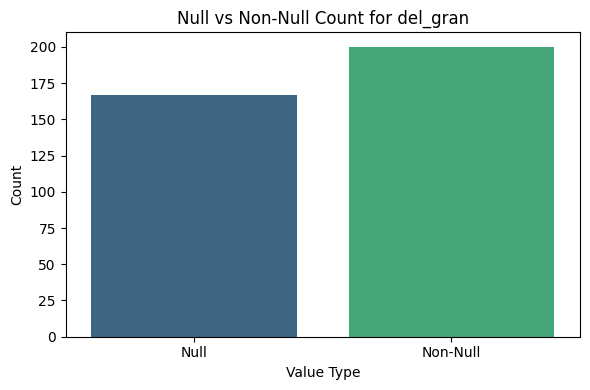

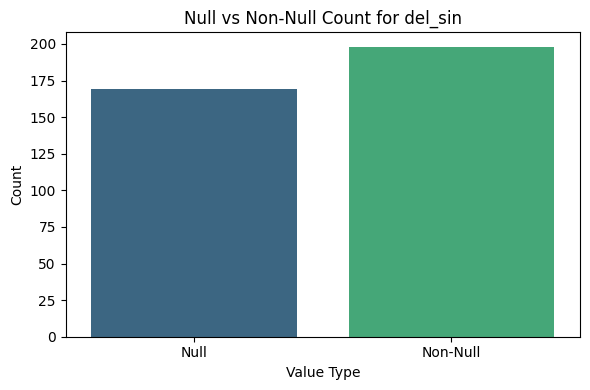

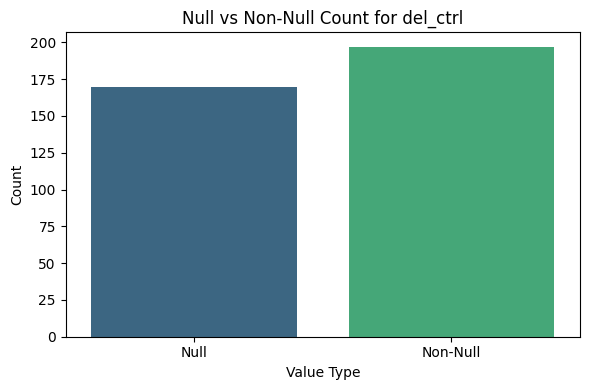

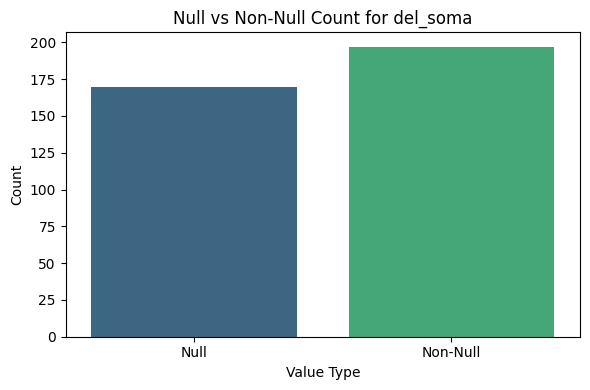

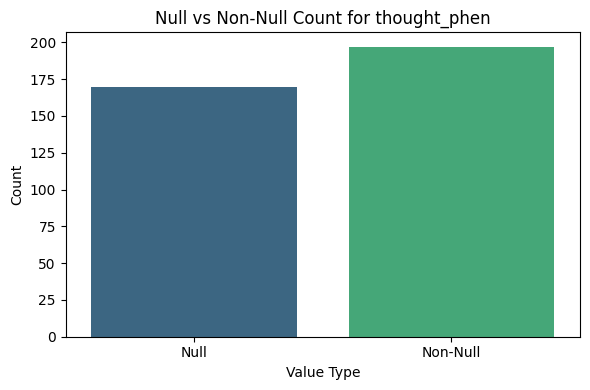

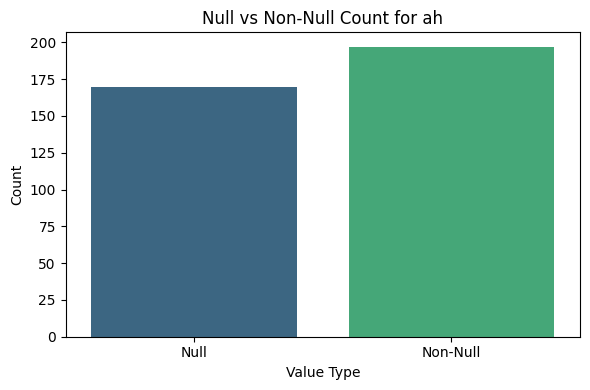

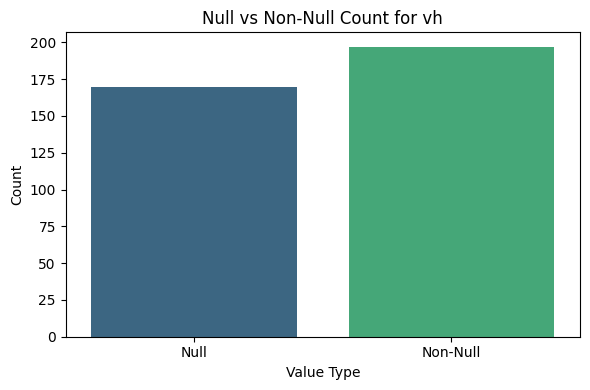

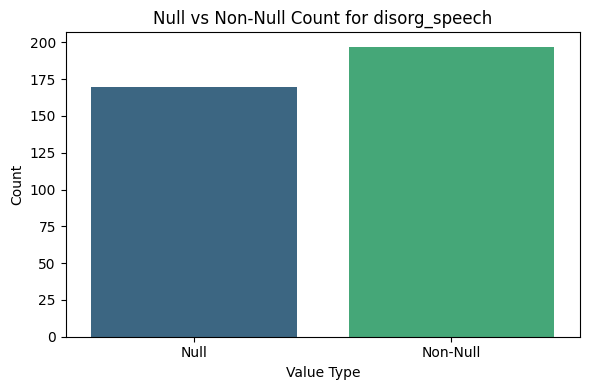

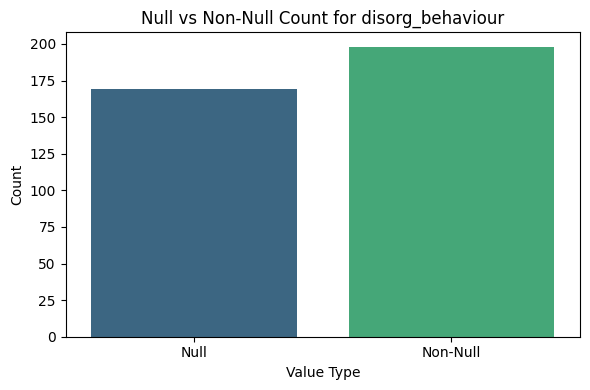

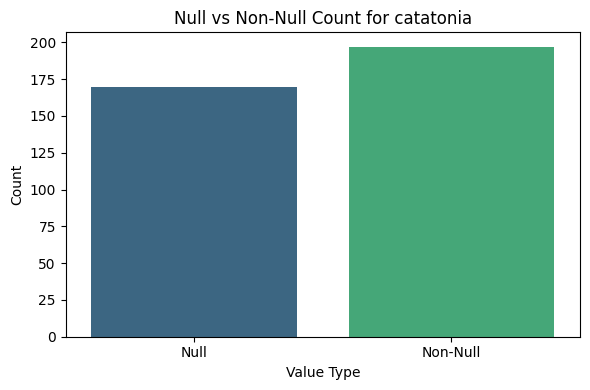

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Loop through each feature with >40% missing data
for feature in above40:
    null_count = df_subset[feature].isna().sum()
    non_null_count = df_subset[feature].count()

    # Prepare data for plotting
    counts = {
        'Null': null_count,
        'Non-Null': non_null_count
    }

    # Convert to DataFrame for Seaborn
    plot_df = pd.DataFrame({
        'Type': list(counts.keys()),
        'Count': list(counts.values())
    })

    plt.figure(figsize=(6, 4))
    sns.barplot(
        data=plot_df,
        x='Type',
        y='Count',
        hue='Type',          # explicitly set hue
        palette='viridis',
        legend=False
    )
    plt.title(f'Null vs Non-Null Count for {feature}')
    plt.ylabel('Count')
    plt.xlabel('Value Type')
    plt.tight_layout()
    plt.show()


In [ ]:
uniqsetofvaluesCat = {}
for col in categorical_cols:
  uniqsetofvaluesCat[col] = set(df_subset[col].to_list())
  print(f"{col} : {set(df_subset[col].to_list())}")


gender : {'Female', nan, 'Male'}
marital_status : {'Widowed', 'Divorced', 'Never married', 'Married', 'Separated', 'Re-married', 'Not available', nan}
education : {'GRADUATE', 'puc', 'graduate ', 'diploma student', 'Graduate - BA', 'PVC II', 'Graduation', 'MA', '12th std', 'SSLC', '11TH STD', 'Primary ', '6th std', '9', 'bcom drop out', 'BA Sanskrit ', 'Graduate', '5th std', 'Primary School', 'BA, DED, CET', '2nd standard', 'Upto 7th Standard', '8th ', '10th pass', 'SSLC fail', '8th std', '7th standard', '7 standard', 'BCom', '10', 'PUC SECOND ', 'Illiterate ', '1st PUC', 'Illiterate', '7TH STD', 'PUC 1ST', 'High school', '8 th class', '5th', '3rd standard', 'high school', 'PUC', nan, 'PRIMARY', 'BTech ', '4th Standard', 'illiterate', 'Graduate ', '5th standard', 'Illeterate', 'Diploma', 'no formal education', '3', 'TCH ', '4th standard', '10 th class ', '9th std', '8th class ', '6th class', 'secondary', 'Diploma in software engineering', '10th standard', 'IInd year degree', '8', 'II n

#### i) Correcting 'total_duration_of_hypomanic_episodes_in_months'

The column `total_duration_of_hypomanic_episodes_in_months` was identified as categorical due to the presence of a date string ('1-11-2002') and 'Unknown' values. This column should represent a numerical duration.

In [ ]:
# Clean and convert 'total_duration_of_hypomanic_episodes_in_months'
df_subset['total_duration_of_hypomanic_episodes_in_months'] = df_subset['total_duration_of_hypomanic_episodes_in_months'].replace({'1-11-2002': pd.NA, 'Unknown': pd.NA})
df_subset['total_duration_of_hypomanic_episodes_in_months'] = pd.to_numeric(df_subset['total_duration_of_hypomanic_episodes_in_months'])

print("Unique values in 'total_duration_of_hypomanic_episodes_in_months' after cleaning:")
print(df_subset['total_duration_of_hypomanic_episodes_in_months'].unique())

#update categorical & numerical columns
categorical_cols = df_subset.select_dtypes(include=['object', 'category']).columns.to_list()
numerical_cols = df_subset.select_dtypes(include=['int64', 'float64']).columns.to_list()


Unique values in 'total_duration_of_hypomanic_episodes_in_months' after cleaning:
[ 2.    0.    4.    1.    1.5   3.     nan  0.5   0.25 18.    6.   11.  ]


#### ii) Standardize Education Levels

The 'education' column contains a wide variety of entries, making it difficult to analyze. I will standardize these into a more manageable set of categories such as 'Illiterate', 'Primary', 'Secondary', 'Diploma', 'Undergraduate', and 'Postgraduate'.

In [ ]:
def standardize_education(edu):
    edu = str(edu).lower().strip()
    if 'illiterate' in edu or 'not literate' in edu or 'no formal education' in edu:
        return 'Illiterate'
    elif 'primary' in edu or 'std' in edu or 'class' in edu or 'grade' in edu or 'th' in edu or 'nd' in edu or edu in ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10']:
        return 'Primary/Secondary'
    elif 'sslc' in edu or 'high school' in edu or 'puc' in edu or 'secondary' in edu or '11' in edu or '12' in edu:
        return 'Secondary/Pre-University'
    elif 'diploma' in edu or 'iti' in edu:
        return 'Diploma/ITI'
    elif 'graduate' in edu or 'b.a' in edu or 'b.e' in edu or 'bcom' in edu or 'b.com' in edu or 'bba' in edu or 'bds' in edu or 'bsc' in edu or 'btech' in edu:
        return 'Undergraduate'
    elif 'msc' in edu or 'm.a' in edu or 'm.e' in edu or 'mcom' in edu or 'ma' in edu or 'phd' in edu or 'bed' in edu:
        return 'Postgraduate'
    else:
        return 'Other/Unknown'

df_subset['education_standard'] = df_subset['education'].apply(standardize_education)
print(df_subset['education_standard'].unique())


['Primary/Secondary' 'Other/Unknown' 'Undergraduate' 'Illiterate'
 'Secondary/Pre-University' 'Diploma/ITI' 'Postgraduate']


In [ ]:
df_subset = df_subset.drop('education', axis=1)

#update categorical & numerical columns
categorical_cols = df_subset.select_dtypes(include=['object', 'category']).columns.to_list()
numerical_cols = df_subset.select_dtypes(include=['int64', 'float64']).columns.to_list()

#### iii) Correcting `rate_response_to_lithium_treatment`

In [ ]:
rate_response_map = {
    '0=no response': 0,
    '1': 1,
    '2': 2,
    '3': 3,
    '4': 4,
    '5': 5,
    '6': 6,
    '7': 7,
    '8': 8,
    '9': 9,
    '10=robust': 10,
    np.nan: np.nan
}
df_subset['rate_response_to_lithium_treatment'] = df_subset['rate_response_to_lithium_treatment'].map(rate_response_map)
df_subset['rate_response_to_lithium_treatment'] = pd.to_numeric(df_subset['rate_response_to_lithium_treatment'])

#update categorical & numerical columns
categorical_cols = df_subset.select_dtypes(include=['object', 'category']).columns.to_list()
numerical_cols = df_subset.select_dtypes(include=['int64', 'float64']).columns.to_list()

#### iv) Standardize 'antipsychotic'

In [ ]:
antipsychotic_map = {
    # Chlorpromazine variants
    'chlorpromazine': 'Chlorpromazine',
    'chloropromazine': 'Chlorpromazine',
    'chloropromazine ': 'Chlorpromazine',
    'chlorpromazine ': 'Chlorpromazine',
    'Chlorpromazine': 'Chlorpromazine',
    'Chlorpromazine ': 'Chlorpromazine',
    'CHLORPROMAZINE': 'Chlorpromazine',
    'Chiorpromazine ': 'Chlorpromazine',
    'Chlorprpmazine': 'Chlorpromazine',
    'Chorpromazine': 'Chlorpromazine',
    'Chlopromazine': 'Chlorpromazine',
    'cpz': 'Chlorpromazine',
    'CPZ': 'Chlorpromazine',
    'CPZ ': 'Chlorpromazine',
    'Cpz': 'Chlorpromazine',
    'CPz': 'Chlorpromazine',

    # Risperidone variants
    'risperidone': 'Risperidone',
    'Risperidone': 'Risperidone',
    'RISPERIDONE': 'Risperidone',
    'risperidone ': 'Risperidone',
    'Risperidone ': 'Risperidone',
    'resperidone': 'Risperidone',
    'RESPERIDON': 'Risperidone',
    'Risp': 'Risperidone',
    'rsnp': 'Risperidone',
    'Rspn': 'Risperidone',
    'RSPN': 'Risperidone',
    'Risperidone CPZ': 'Risperidone + Chlorpromazine',

    # Olanzapine variants
    'Olanzapine': 'Olanzapine',
    'Olanzapine ': 'Olanzapine',
    'Olanzopine': 'Olanzapine',
    'olanzapine': 'Olanzapine',
    'olanzapine ': 'Olanzapine',
    'OLZ': 'Olanzapine',
    'Olz': 'Olanzapine',
    'Oiz': 'Olanzapine',

    # Quetiapine variants
    'Quetiapine': 'Quetiapine',
    'QUETIAPIN': 'Quetiapine',
    'Quitepine': 'Quetiapine',

    # Aripiprazole variants
    'Aripiprazole': 'Aripiprazole',
    'Arip': 'Aripiprazole',

    # Clozapine variants
    'clozapine': 'Clozapine',
    'CLZ': 'Clozapine',

    # Fluphenazine
    'Fluphenazine': 'Fluphenazine',
    'FFZ': 'Fluphenazine',

    # Haloperidol
    'HPL': 'Haloperidol',

    # Carbamazepine (actually anticonvulsant, but appears here)
    'Carbamazepine': 'Carbamazepine',

    # Others
    'amisupride': 'Amisulpride',
    'EPZ': 'Unknown/Other',
    'CBZ': 'Unknown/Other',
    'RSPN': 'Risperidone',
    np.nan: np.nan
}
df_subset['antipsychotic'] = df_subset['antipsychotic'].str.strip().str.lower().map(antipsychotic_map)

#update categorical & numerical columns
categorical_cols = df_subset.select_dtypes(include=['object', 'category']).columns.to_list()
numerical_cols = df_subset.select_dtypes(include=['int64', 'float64']).columns.to_list()

In [ ]:
uniqsetofvaluesNum = {}
for col in numerical_cols:
  uniqsetofvaluesNum[col] = set(df_subset[col].to_list())
  print(f"{col} : {set(df_subset[col].to_list())}")

age : {nan, nan, 11.2, 41.0, nan, 15.2, 17.7, 18.6, nan, 20.9, 21.1, 22.0, 23.7, 24.2, 21.8, 26.5, 24.0, 28.7, 28.2, 30.7, 30.4, 32.5, 33.7, 34.4, 35.2, 36.7, 36.2, 37.1, 38.2, 39.2, 39.1, 41.2, 42.2, 43.2, 44.3, 45.2, 46.1, 47.1, 48.1, 49.1, 51.3, 50.0, 53.3, 54.5, 54.6, 55.7, 55.2, 55.3, 56.7, 57.7, 52.1, 55.1, 58.2, 58.1, 59.1, 61.1, 59.2, 59.6, 67.1, 62.9, 69.5, 67.5, 69.3, 74.2, 75.3, 76.1, 74.8, 75.0, 72.3, nan, 74.5, 74.7, 83.1, 84.0, 77.8, 17.4, nan, 40.3, nan, nan, nan, 19.4, 19.0, nan, 21.4, 21.5, 21.0, 22.9, nan, 23.1, 23.5, 23.0, 25.0, 25.1, nan, 27.5, 46.0, 27.4, nan, 46.5, 28.6, nan, 28.9, 27.0, nan, 29.1, nan, 29.9, 30.0, nan, nan, 30.9, nan, 31.1, 31.6, 31.0, nan, 32.9, 32.1, nan, 33.9, 33.6, nan, 34.3, 34.9, 34.8, 34.2, 35.9, 35.5, 35.0, 35.3, 36.9, 36.1, 36.6, 37.7, 37.2, 37.5, 37.4, 37.6, 38.0, 38.6, 38.1, 38.9, nan, 39.3, 39.8, 39.0, 38.8, 39.6, 40.7, 40.1, 40.4, 40.6, nan, 41.6, 41.7, nan, 41.3, nan, 42.6, 42.4, 42.9, 42.8, 42.0, 43.7, 43.1, 43.4, 42.1, nan, 44.6, 

In [ ]:
print(f"Updated number of categorical columns: {len(categorical_cols)}")
print(f"Updated number of numerical columns: {len(numerical_cols)}")

Updated number of categorical columns: 64
Updated number of numerical columns: 23


### 4.2 Univariate Analysis (One Variable at a Time) BEFORE Imputation and Duplicate Removal


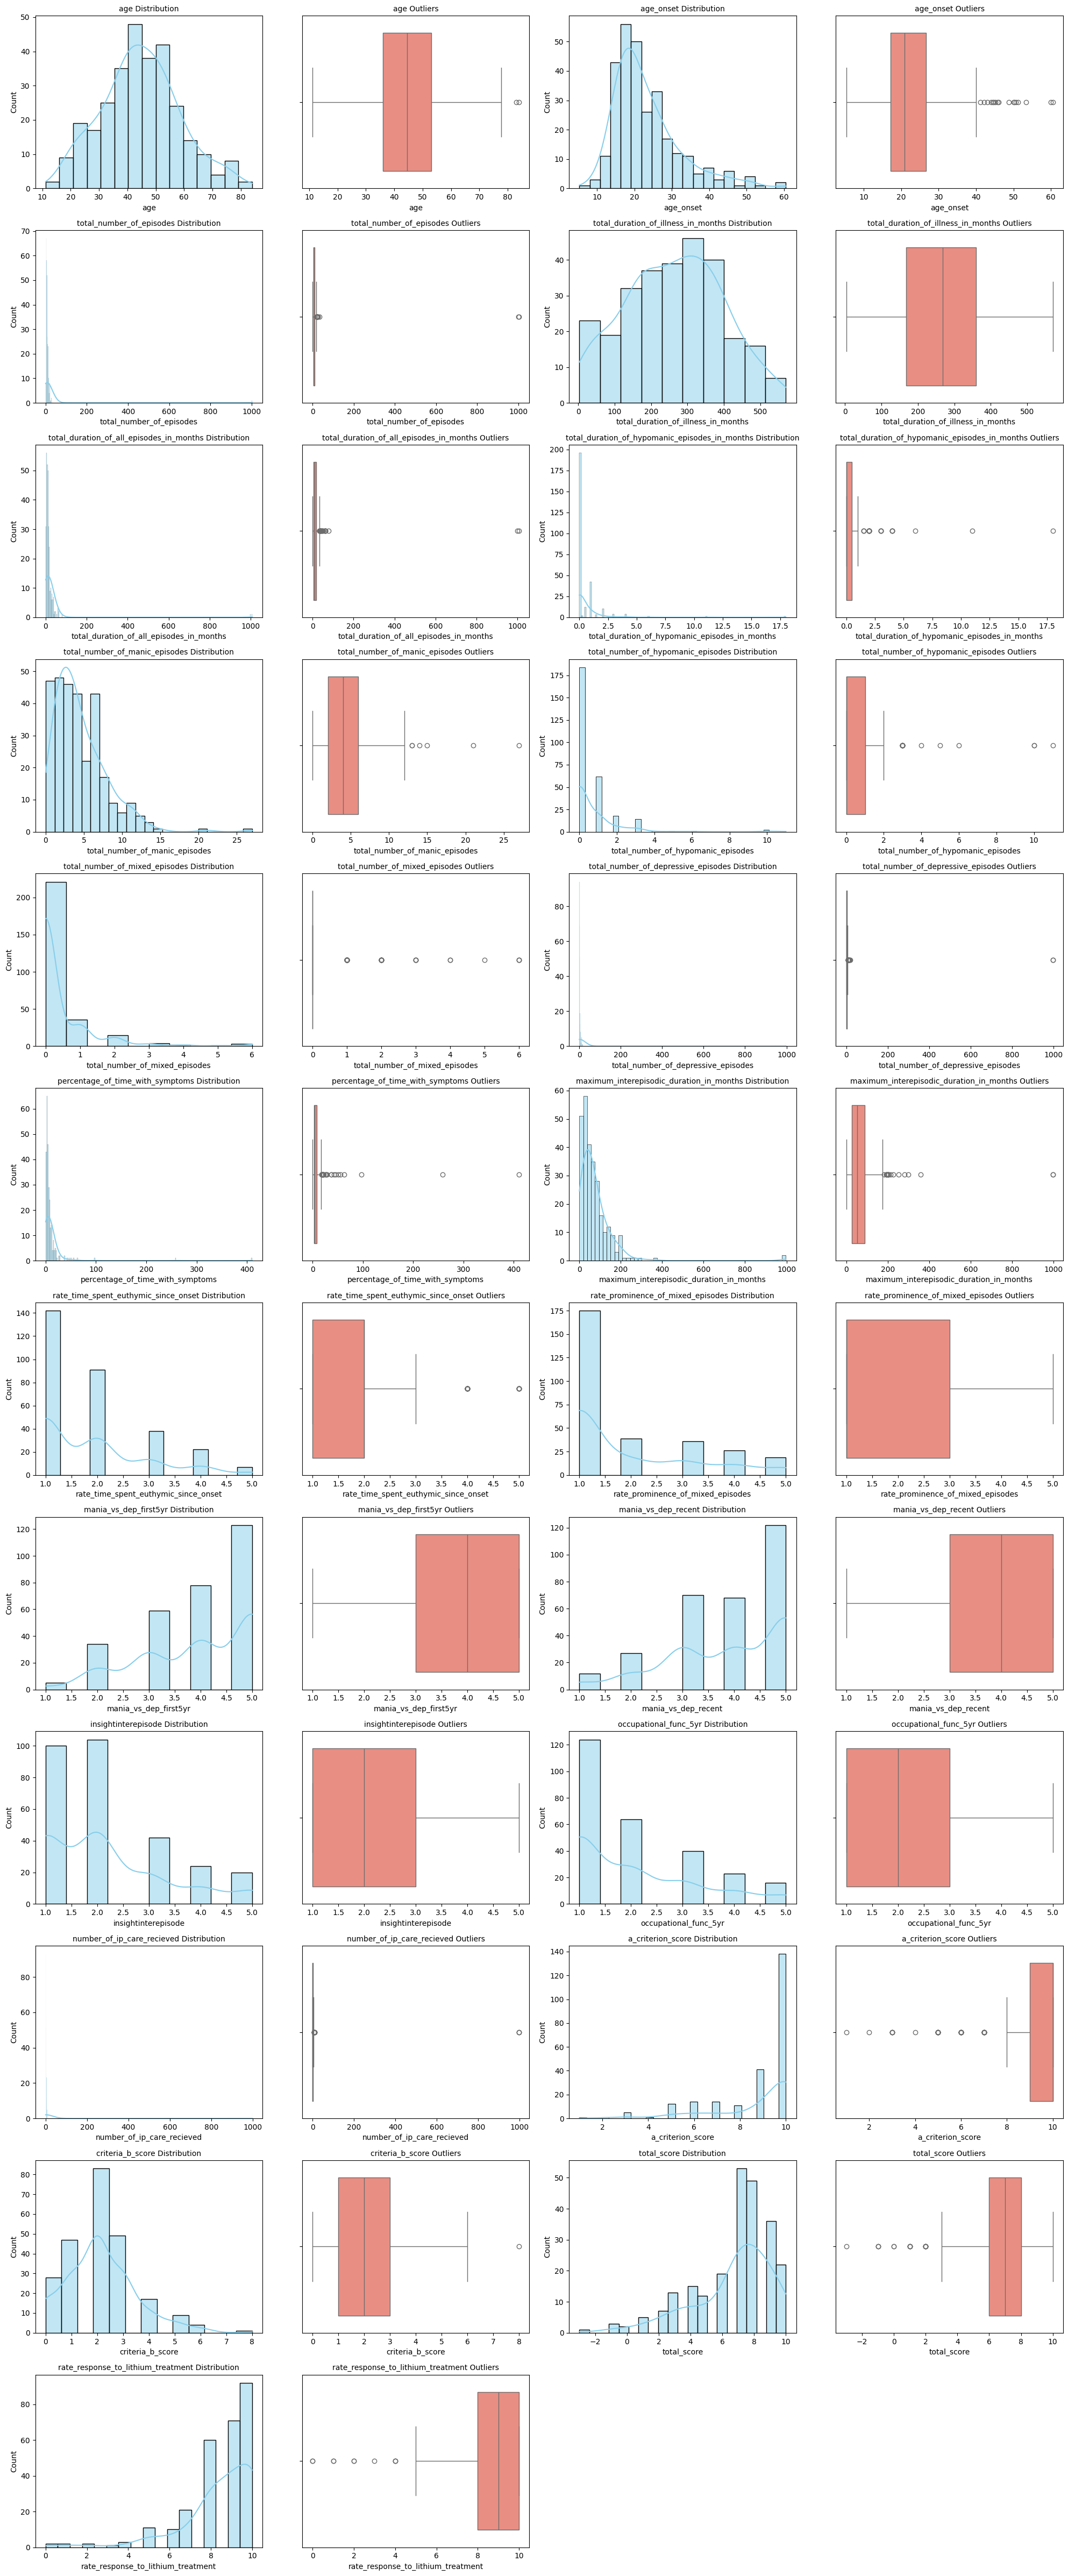

Skipping 0 categorical columns due to high cardinality (>15 unique values).


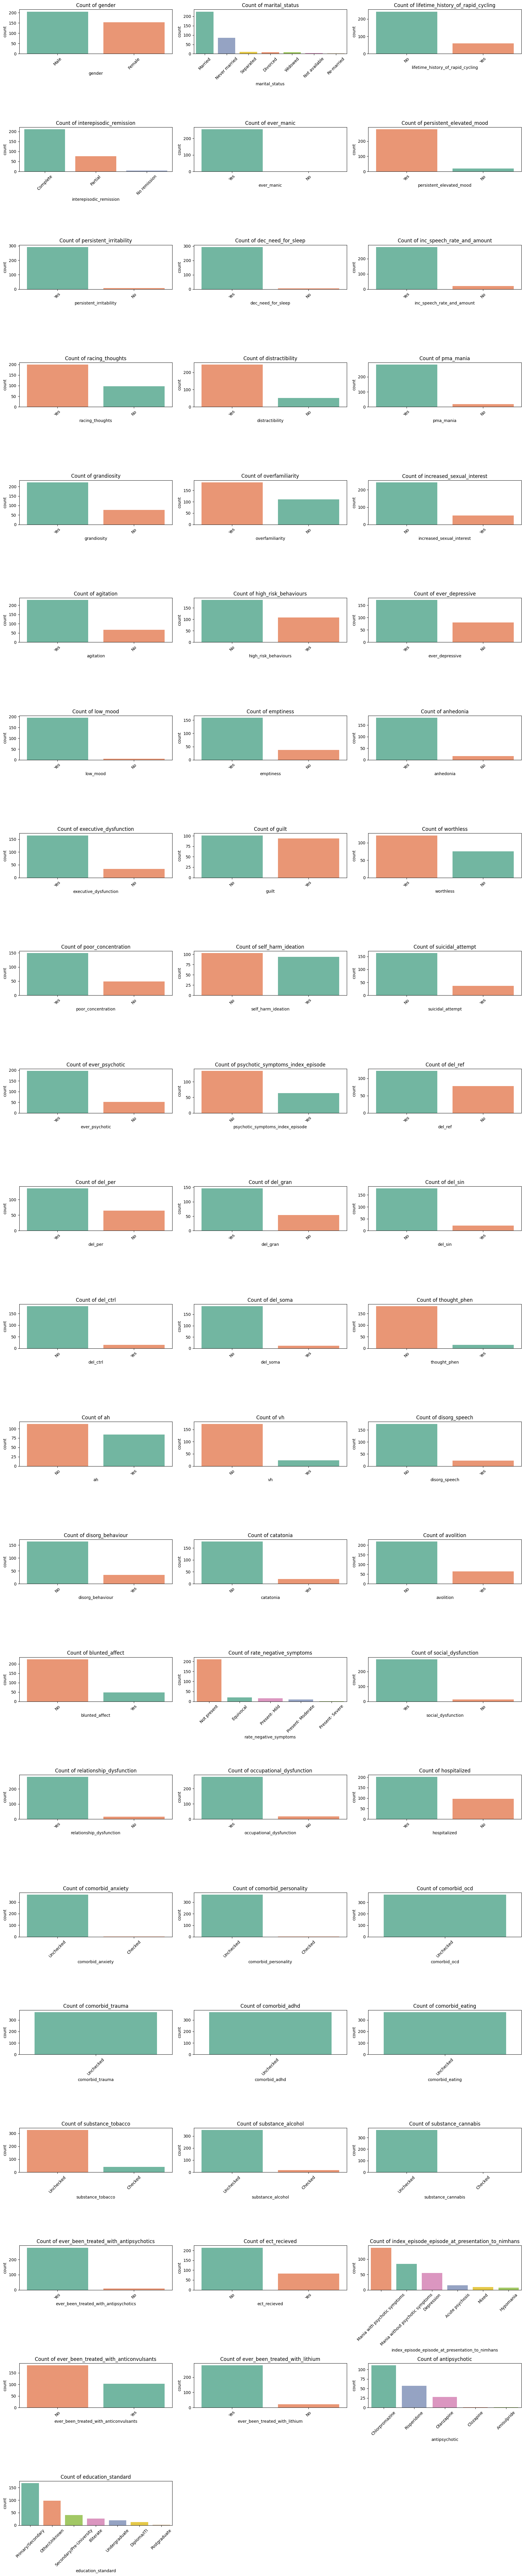

In [ ]:
import math

# --- NUMERICAL DISTRIBUTIONS (Grid Layout) ---
# We will plot 4 variables (8 subplots total) per row block to save vertical scrolling space
num_plots = len(numerical_cols)
cols_per_row = 2  # 2 variables per row (each getting a Hist and a Boxplot)
rows = math.ceil(num_plots / cols_per_row)

fig, axes = plt.subplots(rows, cols_per_row * 2, figsize=(20, rows * 4))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    # Skip if the column is entirely null (boxplot cannot be drawn)
    if df_subset[col].dropna().empty:
        # Hide the corresponding subplots if they exist
        if (i * 2) < len(axes):
            fig.delaxes(axes[i * 2])
        if (i * 2 + 1) < len(axes):
            fig.delaxes(axes[i * 2 + 1])
        continue

    idx_hist = i * 2
    idx_box = i * 2 + 1

    # Histogram
    sns.histplot(df_subset[col], kde=True, ax=axes[idx_hist], color='skyblue')
    axes[idx_hist].set_title(f'{col} Distribution', fontsize=10)

    # Boxplot
    sns.boxplot(x=df_subset[col], ax=axes[idx_box], color='salmon')
    axes[idx_box].set_title(f'{col} Outliers', fontsize=10)

# Hide any leftover empty subplots in the grid
for j in range(num_plots * 2, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


# --- CATEGORICAL COUNTS (Filtered Grid Layout) ---
# Filter out text/ID columns with more than 15 unique values to avoid messy charts
clean_categorical_cols = [col for col in categorical_cols if df_subset[col].nunique() <= 15]
print(f"Skipping {len(categorical_cols) - len(clean_categorical_cols)} categorical columns due to high cardinality (>15 unique values).")

cat_plots = len(clean_categorical_cols)
cat_cols_per_row = 3
cat_rows = math.ceil(cat_plots / cat_cols_per_row)

if cat_plots > 0:
    fig, axes = plt.subplots(cat_rows, cat_cols_per_row, figsize=(18, cat_rows * 4))
    axes = axes.flatten()

    for i, col in enumerate(clean_categorical_cols):
        # Setting hue=col and legend=False satisfies the new Seaborn requirements
        sns.countplot(
            data=df_subset,
            x=col,
            order=df_subset[col].value_counts().index,
            ax=axes[i],
            hue=col,
            palette='Set2',
            legend=False
        )
        axes[i].set_title(f'Count of {col}', fontsize=12)
        axes[i].tick_params(axis='x', rotation=45)


    # Hide leftover subplots
    for j in range(cat_plots, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

#### v) Remove duplicate rows

In [ ]:
all_duplicates = df_subset.duplicated().sum()
print(all_duplicates)

25


In [ ]:
#Identifying and removing duplicate rows
print("Initial number of rows:", len(df_subset))
df_subset.drop_duplicates(inplace=True)
print("Number of rows after removing duplicates:", len(df_subset))

Initial number of rows: 367
Number of rows after removing duplicates: 342


#### vi) Missing value Imputation

In [ ]:
df_imputed = df_subset

In [ ]:
#full MICE imputation
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

mice_imputer = IterativeImputer(random_state=42)
df_imputed[numerical_cols] = mice_imputer.fit_transform(df_subset[numerical_cols])

print("Missing values after MICE imputation for numerical columns:")
print(df_imputed[numerical_cols].isnull().sum())

Missing values after MICE imputation for numerical columns:
age                                               0
age_onset                                         0
total_number_of_episodes                          0
total_duration_of_illness_in_months               0
total_duration_of_all_episodes_in_months          0
total_duration_of_hypomanic_episodes_in_months    0
total_number_of_manic_episodes                    0
total_number_of_hypomanic_episodes                0
total_number_of_mixed_episodes                    0
total_number_of_depressive_episodes               0
percentage_of_time_with_symptoms                  0
maximum_interepisodic_duration_in_months          0
rate_time_spent_euthymic_since_onset              0
rate_prominence_of_mixed_episodes                 0
mania_vs_dep_first5yr                             0
mania_vs_dep_recent                               0
insightinterepisode                               0
occupational_func_5yr                             0
numb

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


In [ ]:
#the below columns are found to have severe bias during median imputation,
#so these cols can be imputed using another imputation technique
filtered_numerical_cols = [
    'age',
    'total_duration_of_illness_in_months',
    'criteria_b_score',
    'total_score',
    'a_criterion_score',
    'occupational_func_5yr',
    'rate_time_spent_euthymic_since_onset',
    'insightinterepisode',
    'mania_vs_dep_first5yr',
    'mania_vs_dep_recent'
]

remaining_numerical_cols = [col for col in numerical_cols if col not in filtered_numerical_cols]

print("Remaining Numerical Columns (excluding extracted features):")
print(remaining_numerical_cols)

Remaining Numerical Columns (excluding extracted features):
['age_onset', 'total_number_of_episodes', 'total_duration_of_all_episodes_in_months', 'total_duration_of_hypomanic_episodes_in_months', 'total_number_of_manic_episodes', 'total_number_of_hypomanic_episodes', 'total_number_of_mixed_episodes', 'total_number_of_depressive_episodes', 'percentage_of_time_with_symptoms', 'maximum_interepisodic_duration_in_months', 'rate_prominence_of_mixed_episodes', 'number_of_ip_care_recieved', 'rate_response_to_lithium_treatment']


In [ ]:
# Fill the remaining missing numerical fields with 'Median value'
for col in remaining_numerical_cols:
  df_imputed[col] = df_subset[col].fillna(df_subset[col].median())


In [ ]:
#using MICE imputation for filtered columns
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

filtered_numerical_cols.remove('criteria_b_score') #this feature again found to have severe bias even in MICE, so impute using PMM later

mice_imputer = IterativeImputer(random_state=42)
df_imputed[filtered_numerical_cols] = mice_imputer.fit_transform(df_subset[filtered_numerical_cols])

print("Missing values after MICE imputation for filtered numerical columns:")
print(df_imputed[filtered_numerical_cols].isnull().sum())

Missing values after MICE imputation for filtered numerical columns:
age                                     0
total_duration_of_illness_in_months     0
total_score                             0
a_criterion_score                       0
occupational_func_5yr                   0
rate_time_spent_euthymic_since_onset    0
insightinterepisode                     0
mania_vs_dep_first5yr                   0
mania_vs_dep_recent                     0
dtype: int64


In [ ]:
print(df_imputed.isna().sum())

age                                                   0
gender                                                3
marital_status                                       14
age_onset                                             0
total_number_of_episodes                              0
                                                   ... 
index_episode_episode_at_presentation_to_nimhans     35
ever_been_treated_with_anticonvulsants               58
ever_been_treated_with_lithium                       42
antipsychotic                                       144
education_standard                                    0
Length: 87, dtype: int64


##### using Predictive Mean Matching (PMM) for `criteria_b_score`

In [ ]:
from scipy import stats
import pandas as pd
import numpy as np

results = []

for col in categorical_cols:
    # only use rows where both criteria_b_score and this categorical column are present
    valid = df_imputed[[col, 'criteria_b_score']].dropna()

    if valid[col].nunique() < 2 or len(valid) < 10:
        continue  # skip columns with no variation or too little data

    groups = [valid.loc[valid[col] == level, 'criteria_b_score'] for level in valid[col].unique()]

    # Kruskal-Wallis handles both binary and multi-level, and doesn't assume normality
    stat, p_value = stats.kruskal(*groups)

    results.append({'column': col, 'kruskal_stat': stat, 'p_value': p_value, 'n_valid': len(valid)})

results_df = pd.DataFrame(results).sort_values('p_value')
print(results_df.to_string())

                                              column  kruskal_stat   p_value  n_valid
25                                self_harm_ideation      8.830510  0.002962      197
10                                   distractibility      6.941044  0.008424      296
33                                          del_ctrl      5.809087  0.015944      197
24                                poor_concentration      5.799086  0.016035      198
29                                           del_ref      5.417989  0.019930      200
22                                             guilt      5.015715  0.025118      195
23                                         worthless      4.730583  0.029631      196
57                    ever_been_treated_with_lithium      4.500648  0.033882      300
59                                education_standard     12.339912  0.054801      342
16                              high_risk_behaviours      3.578681  0.058526      292
5                           persistent_elevated_mood  

In [ ]:
# Bonferroni-style guard against false positives given many tests
alpha = 0.05 / len(results_df)  # conservative correction for multiple comparisons

significant_predictors = results_df[results_df['p_value'] < alpha]
print(f"\n{len(significant_predictors)} columns significantly associated with criteria_b_score:")
print(significant_predictors[['column', 'p_value']])


0 columns significantly associated with criteria_b_score:
Empty DataFrame
Columns: [column, p_value]
Index: []


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import OrdinalEncoder

# use only rows where criteria_b_score is observed (not yet imputed)
train_data = df_imputed.dropna(subset=['criteria_b_score']).copy()

X_cat = train_data[categorical_cols].copy()
# encode categoricals as integers (RF handles this fine, it's just splits)
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_cat_encoded = encoder.fit_transform(X_cat.astype(str))

y = train_data['criteria_b_score']

rf = RandomForestRegressor(n_estimators=300, random_state=42, max_depth=5)
rf.fit(X_cat_encoded, y)

importance_df = pd.DataFrame({
    'column': categorical_cols,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

print(importance_df.head(15))

                                              column  importance
6                            persistent_irritability    0.065375
63                                education_standard    0.051290
43                            rate_negative_symptoms    0.047997
57             ever_been_treated_with_antipsychotics    0.047036
59  index_episode_episode_at_presentation_to_nimhans    0.043597
62                                     antipsychotic    0.042585
54                                 substance_tobacco    0.041561
29                                           del_ref    0.035826
31                                          del_gran    0.034969
60            ever_been_treated_with_anticonvulsants    0.031713
41                                         avolition    0.030137
10                                   distractibility    0.029480
25                                self_harm_ideation    0.026328
11                                         pma_mania    0.024481
0                        

In [ ]:
# Take the union of top statistical hits and top RF importances
top_kruskal = set(significant_predictors['column'])
top_rf = set(importance_df.head(15)['column'])

final_predictors = list(top_kruskal | top_rf)
print(f"Final predictor set ({len(final_predictors)} columns):")
print(final_predictors)

Final predictor set (15 columns):
['substance_tobacco', 'distractibility', 'pma_mania', 'del_ref', 'education_standard', 'rate_negative_symptoms', 'index_episode_episode_at_presentation_to_nimhans', 'ever_been_treated_with_anticonvulsants', 'avolition', 'ever_been_treated_with_antipsychotics', 'antipsychotic', 'self_harm_ideation', 'persistent_irritability', 'gender', 'del_gran']


In [ ]:
!pip install miceforest

In [ ]:
import miceforest as mf

# 1. Reset your index
df_imputed = df_imputed.reset_index(drop=True)

# 2. Fix hidden infinity values in numerical columns
df_imputed.replace([np.inf, -np.inf], np.nan, inplace=True)

full_input = df_imputed[numerical_cols + final_predictors].copy()

# 3. Handle object & category fields safely
obj_cols = full_input.select_dtypes(include=['object']).columns
for col in obj_cols:
    full_input[col] = full_input[col].astype('category')

# Crucial: Drop unused category levels that screw up tree distributions
for col in full_input.select_dtypes(include=['category']).columns:
    full_input[col] = full_input[col].cat.remove_unused_categories()

# Initialize the kernel safely
# kernel expects a pandas DataFrame with your numeric columns
kernel = mf.ImputationKernel(
    full_input,                      # your dataframe with missing values (pre-imputation)
    variable_schema={
        'criteria_b_score': [c for c in full_input.columns if c != 'criteria_b_score'],
        'a_criterion_score': [c for c in full_input.columns if c != 'a_criterion_score'],
    },
    num_datasets=1,
    mean_match_candidates=5, # PMM: number of donor candidates to sample from
    random_state=42
)

kernel.mice(
    iterations=5,
    min_data_in_leaf=15,
    cat_smooth=10.0
)

completed_numeric = kernel.complete_data(dataset=0)

# 4. Write ONLY criteria_b_score back into df_imputed — categorical cols remain untouched
df_imputed['criteria_b_score'] = completed_numeric['criteria_b_score']

df_imputed['criteria_b_score'] = df_imputed['criteria_b_score'].round()

print(df_imputed['criteria_b_score'].describe())
print(df_imputed['criteria_b_score'].value_counts().sort_index())
# confirm min >= 0 and max <= 8, and all values are whole numbers

count    342.000000
mean       2.073099
std        1.202603
min       -4.000000
25%        2.000000
50%        2.000000
75%        2.000000
max        8.000000
Name: criteria_b_score, dtype: float64
criteria_b_score
-4.0      1
 0.0     28
 1.0     47
 2.0    184
 3.0     51
 4.0     17
 5.0      9
 6.0      4
 8.0      1
Name: count, dtype: int64


##### imputing Categorical features

In [ ]:
df_imputed = df_imputed.replace("Unknown", np.nan).copy()

# 1. Confirm the correct gatekeeper column with real crosstabs first
candidate_parents = ['ever_psychotic', 'psychotic_symptoms_index_episode']
skip_logic_map = {
    'del_ref':            {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'del_per':            {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'del_gran':           {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'del_sin':            {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'del_ctrl':           {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'del_soma':           {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'thought_phen':       {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'ah':                 {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'vh':                 {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'catatonia':          {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'disorg_speech':      {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'disorg_behaviour':   {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'avolition':          {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'blunted_affect':     {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'rate_negative_symptoms': {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
}

for child_col in skip_logic_map.keys():
    print(f"\n=== {child_col} ===")
    for parent in candidate_parents:
        ct = pd.crosstab(df_imputed[parent], df_imputed[child_col].isna())
        print(f"vs {parent}:\n{ct}\n")


=== del_ref ===
vs ever_psychotic:
del_ref         False  True 
ever_psychotic              
No                  1     50
Yes               195      2

vs psychotic_symptoms_index_episode:
del_ref                           False  True 
psychotic_symptoms_index_episode              
No                                   83     52
Yes                                  58      6


=== del_per ===
vs ever_psychotic:
del_per         False  True 
ever_psychotic              
No                  1     50
Yes               196      1

vs psychotic_symptoms_index_episode:
del_per                           False  True 
psychotic_symptoms_index_episode              
No                                   83     52
Yes                                  58      6


=== del_gran ===
vs ever_psychotic:
del_gran        False  True 
ever_psychotic              
No                  1     50
Yes               195      2

vs psychotic_symptoms_index_episode:
del_gran                          False  True 
psyc

In [ ]:
# 2. Fix skip_logic_map's parent column based on what step 1 shows
skip_logic_map = {
    'del_ref':            {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'del_per':            {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'del_gran':           {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'del_sin':            {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'del_ctrl':           {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'del_soma':           {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'thought_phen':       {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'ah':                 {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'vh':                 {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'catatonia':          {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'disorg_speech':      {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    'disorg_behaviour':   {'parent': 'ever_psychotic', 'trigger_value': 'Yes'},
    # avolition, blunted_affect, rate_negative_symptoms removed —
    # not conditionally missing on psychosis history; handle their
    # NaNs with standard (non-skip-logic) imputation instead
}


In [ ]:
for col in categorical_cols:    df_imputed[col] = df_imputed[col].astype('category')

# 3. Apply recoding BEFORE any "Unknown" fill
for child_col, rule in skip_logic_map.items():
    parent_col = rule['parent']
    condition = (df_imputed[parent_col] == 'No') & (df_imputed[child_col].isna())
    n_recoded = condition.sum()
    if 'No' not in df_imputed[child_col].cat.categories:
        df_imputed[child_col] = df_imputed[child_col].cat.add_categories('No')
    df_imputed.loc[condition, child_col] = 'No'
    print(f"{child_col}: recoded {n_recoded} rows from NaN → 'No' based on {parent_col}=='No'")

del_ref: recoded 50 rows from NaN → 'No' based on ever_psychotic=='No'
del_per: recoded 50 rows from NaN → 'No' based on ever_psychotic=='No'
del_gran: recoded 50 rows from NaN → 'No' based on ever_psychotic=='No'
del_sin: recoded 50 rows from NaN → 'No' based on ever_psychotic=='No'
del_ctrl: recoded 50 rows from NaN → 'No' based on ever_psychotic=='No'
del_soma: recoded 50 rows from NaN → 'No' based on ever_psychotic=='No'
thought_phen: recoded 50 rows from NaN → 'No' based on ever_psychotic=='No'
ah: recoded 50 rows from NaN → 'No' based on ever_psychotic=='No'
vh: recoded 50 rows from NaN → 'No' based on ever_psychotic=='No'
catatonia: recoded 50 rows from NaN → 'No' based on ever_psychotic=='No'
disorg_speech: recoded 50 rows from NaN → 'No' based on ever_psychotic=='No'
disorg_behaviour: recoded 50 rows from NaN → 'No' based on ever_psychotic=='No'


In [ ]:
# 4. Check genuine residual missingness
remaining_missing = df_imputed[list(skip_logic_map.keys())].isna().sum()
print(remaining_missing[remaining_missing > 0])


del_ref             92
del_per             91
del_gran            92
del_sin             94
del_ctrl            95
del_soma            95
thought_phen        95
ah                  95
vh                  95
catatonia           95
disorg_speech       95
disorg_behaviour    94
dtype: int64


In [ ]:
# 5. Only now fill true leftover missingness (small, by design) with "Unknown" or proper imputation
for col in categorical_cols:
    if 'Unknown' not in df_imputed[col].cat.categories:
        df_imputed[col] = df_imputed[col].cat.add_categories('Unknown')
    df_imputed[col] = df_imputed[col].fillna("Unknown")

In [ ]:
# Updated numerical and categorical columns count
print(f"Updated categorical column count: {len(categorical_cols)}")
print(f"Updated numerical column count: {len(numerical_cols)}")

Updated categorical column count: 64
Updated numerical column count: 23


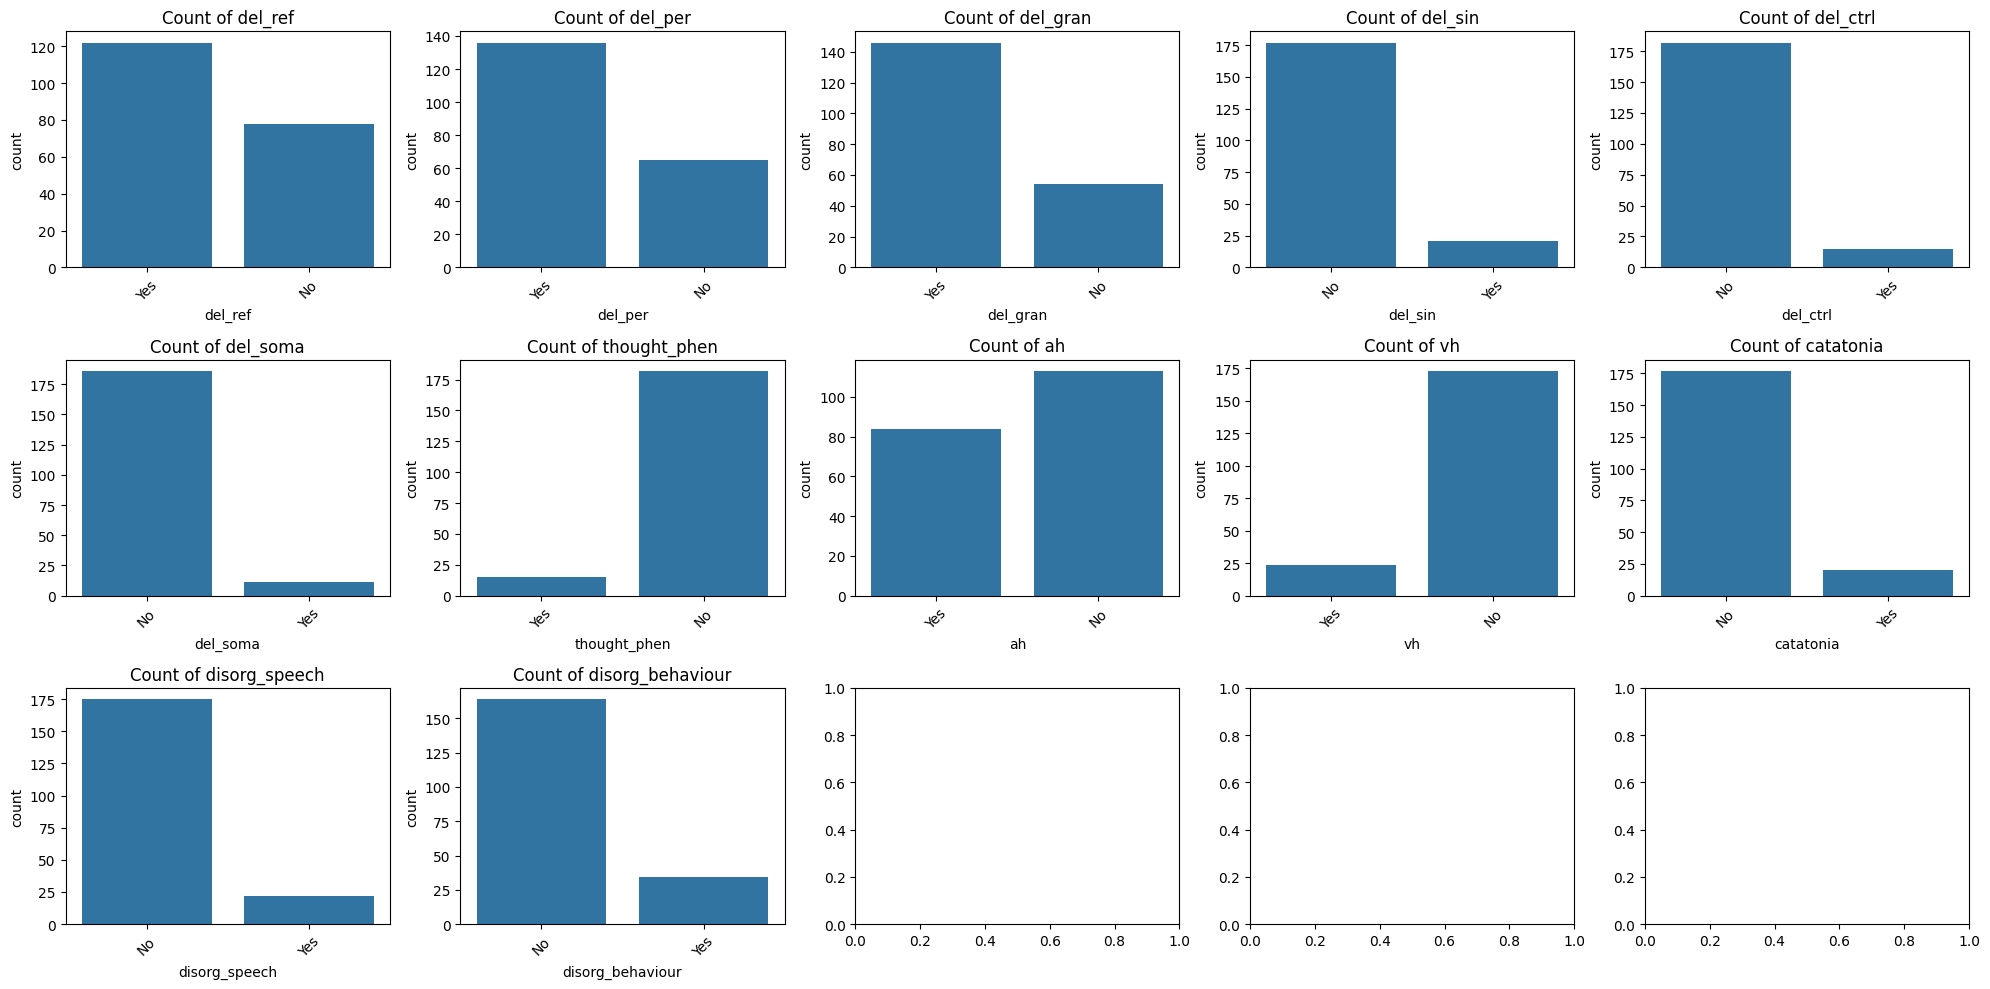

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(3, 5, figsize=(20, 10))
for ax, col in zip(axes.flat, list(skip_logic_map.keys())):
    sns.countplot(x=df[col], ax=ax)
    ax.set_title(f'Count of {col}')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

### 4.3 Univariate Analysis (One Variable at a Time) AFTER Imputation and Duplicate Removal



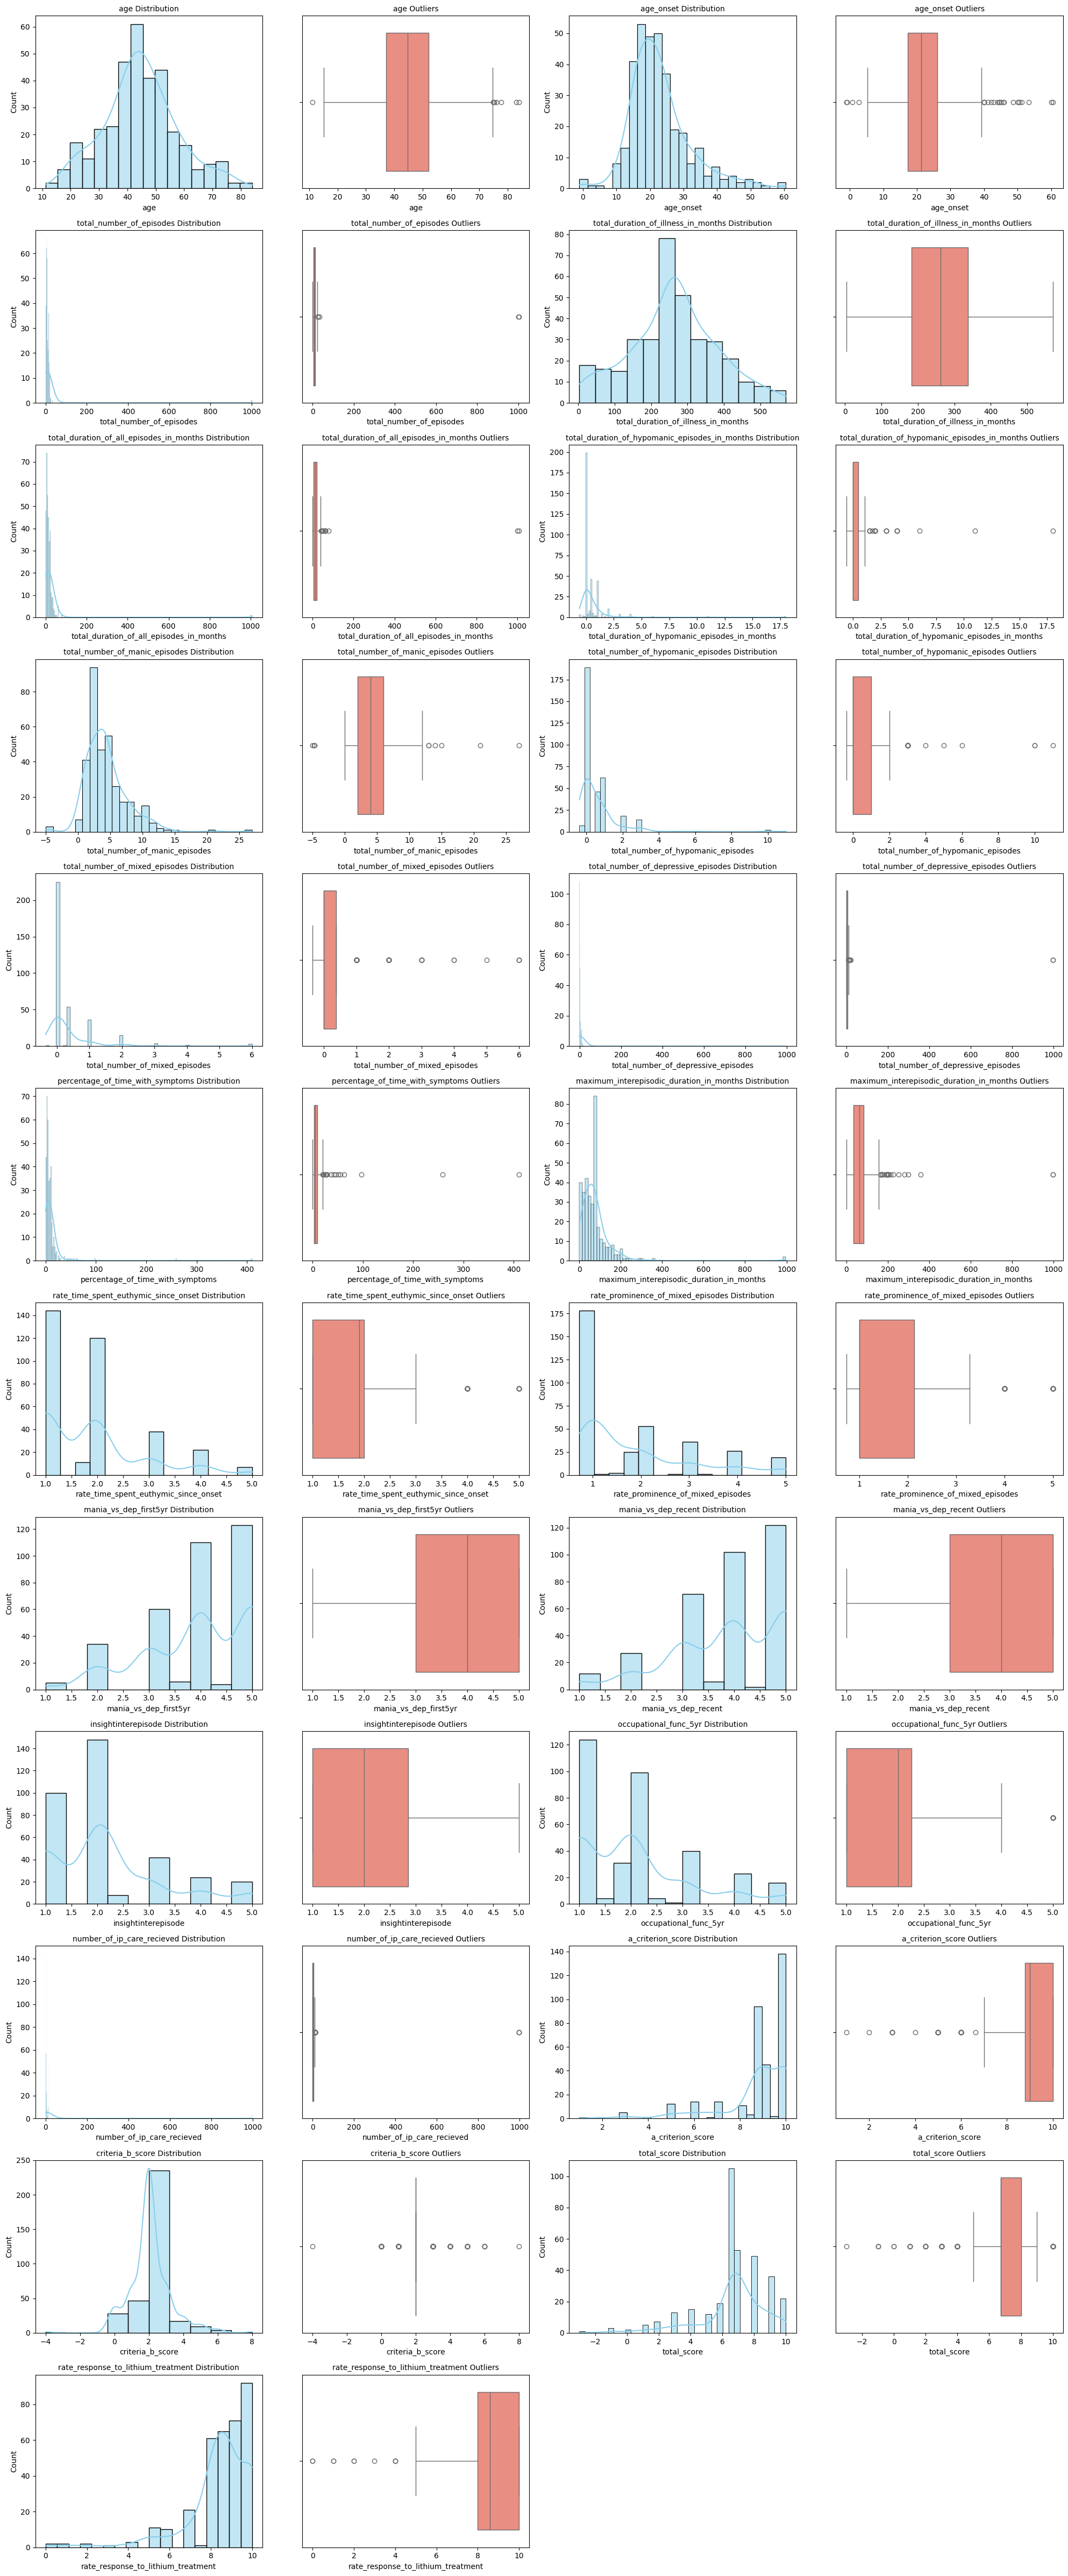

Skipping 0 categorical columns due to high cardinality (>15 unique values).


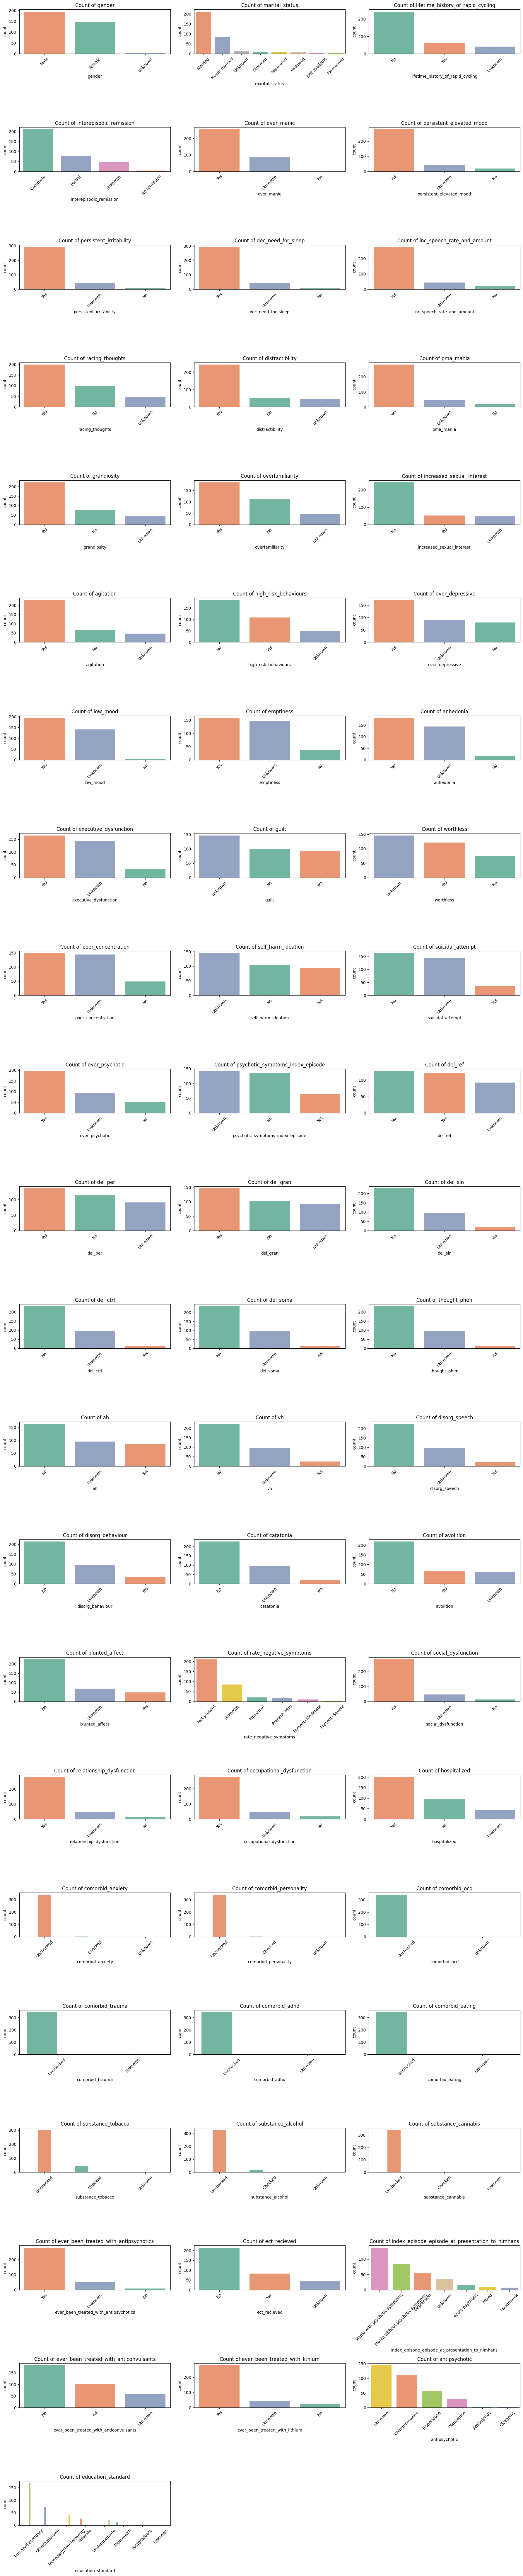

In [ ]:
import math

# --- NUMERICAL DISTRIBUTIONS (Grid Layout) ---
# We will plot 4 variables (8 subplots total) per row block to save vertical scrolling space
num_plots = len(numerical_cols)
cols_per_row = 2  # 2 variables per row (each getting a Hist and a Boxplot)
rows = math.ceil(num_plots / cols_per_row)

fig, axes = plt.subplots(rows, cols_per_row * 2, figsize=(20, rows * 4))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    # Skip if the column is entirely null (boxplot cannot be drawn)
    if df_subset[col].dropna().empty:
        # Hide the corresponding subplots if they exist
        if (i * 2) < len(axes):
            fig.delaxes(axes[i * 2])
        if (i * 2 + 1) < len(axes):
            fig.delaxes(axes[i * 2 + 1])
        continue

    idx_hist = i * 2
    idx_box = i * 2 + 1

    # Histogram
    sns.histplot(df_imputed[col], kde=True, ax=axes[idx_hist], color='skyblue')
    axes[idx_hist].set_title(f'{col} Distribution', fontsize=10)

    # Boxplot
    sns.boxplot(x=df_imputed[col], ax=axes[idx_box], color='salmon')
    axes[idx_box].set_title(f'{col} Outliers', fontsize=10)

# Hide any leftover empty subplots in the grid
for j in range(num_plots * 2, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


# --- CATEGORICAL COUNTS (Filtered Grid Layout) ---
# Filter out text/ID columns with more than 15 unique values to avoid messy charts
clean_categorical_cols = [col for col in categorical_cols if df_imputed[col].nunique() <= 15]
print(f"Skipping {len(categorical_cols) - len(clean_categorical_cols)} categorical columns due to high cardinality (>15 unique values).")

cat_plots = len(clean_categorical_cols)
cat_cols_per_row = 3
cat_rows = math.ceil(cat_plots / cat_cols_per_row)

if cat_plots > 0:
    fig, axes = plt.subplots(cat_rows, cat_cols_per_row, figsize=(18, cat_rows * 4))
    axes = axes.flatten()

    for i, col in enumerate(clean_categorical_cols):
        # Setting hue=col and legend=False satisfies the new Seaborn requirements
        sns.countplot(
            data=df_imputed,
            x=col,
            order=df_imputed[col].value_counts().index,
            ax=axes[i],
            hue=col,
            palette='Set2',
            legend=False
        )
        axes[i].set_title(f'Count of {col}', fontsize=12)
        axes[i].tick_params(axis='x', rotation=45)


    # Hide leftover subplots
    for j in range(cat_plots, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()


### 5. Feature Transformation

In [ ]:
#from sklearn.preprocessing import StandardScaler

# Create a copy of the original subset
#Bipolar_preprocessed = df_subset.copy()

# 1. Identify categorical columns
#cols_one_hot_encode = Bipolar_preprocessed.select_dtypes(
    #include=["object", "category"]
#).columns.tolist()

# 2. Apply One-Hot Encoding
#if cols_one_hot_encode:
    #print("Applying One-Hot Encoding to:")
    #print(cols_one_hot_encode)

    #Bipolar_preprocessed = pd.get_dummies(
        #Bipolar_preprocessed,
        #columns=cols_one_hot_encode,
        #drop_first=True
    #)

# 3. Standard Scaling
#scaler_standard = StandardScaler()

#Bipolar_preprocessed[numerical_cols] = scaler_standard.fit_transform(
    #Bipolar_preprocessed[numerical_cols]
#)

#print("Final Preprocessed Dataset:")
#print(Bipolar_preprocessed)

In [ ]:
from sklearn.preprocessing import MinMaxScaler, RobustScaler

# Let's try MinMaxScaler as an alternative to StandardScaler

# Create a fresh copy of the original df_subset before any scaling
# (Assuming you want to re-run the process from before scaling,
# or you would apply this directly to `df_subset` before one-hot encoding)

# For demonstration, let's re-run a portion of the preprocessing with MinMaxScaler
# In a real scenario, you would choose ONE scaler and apply it.

# Re-create Bipolar_preprocessed for MinMaxScaler demonstration
# (This assumes you are re-running the 'Feature Transformation' section from scratch for comparison)
Bipolar_preprocessed = df_imputed.copy()

# 1. Identify categorical columns (same as before)
cols_one_hot_encode_minmax = Bipolar_preprocessed.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# 2. Apply One-Hot Encoding (same as before)
if cols_one_hot_encode_minmax:
    print("Applying One-Hot Encoding to (for MinMaxScaler demo):")
    print(cols_one_hot_encode_minmax)
    Bipolar_preprocessed = pd.get_dummies(
        Bipolar_preprocessed,
        columns=cols_one_hot_encode_minmax,
        drop_first=True
    )

# 3. Apply MinMaxScaler
scaler_minmax = MinMaxScaler()

# Ensure numerical_cols is up-to-date with the columns present in Bipolar_preprocessed_minmax
current_numerical_cols = Bipolar_preprocessed.select_dtypes(include=['float64', 'int64']).columns.tolist()

print("\nApplying MinMaxScaler to numerical columns:")
print(current_numerical_cols)

Bipolar_preprocessed[current_numerical_cols] = scaler_minmax.fit_transform(
    Bipolar_preprocessed[current_numerical_cols]
)

print("\nFinal Preprocessed Dataset with MinMaxScaler (first 5 rows):")
display(Bipolar_preprocessed.head())

# You would then proceed to run your clustering algorithms on `Bipolar_preprocessed_minmax`
# and compare the results to those obtained with StandardScaler.

Applying One-Hot Encoding to (for MinMaxScaler demo):
['gender', 'marital_status', 'lifetime_history_of_rapid_cycling', 'interepisodic_remission', 'ever_manic', 'persistent_elevated_mood', 'persistent_irritability', 'dec_need_for_sleep', 'inc_speech_rate_and_amount', 'racing_thoughts', 'distractibility', 'pma_mania', 'grandiosity', 'overfamiliarity', 'increased_sexual_interest', 'agitation', 'high_risk_behaviours', 'ever_depressive', 'low_mood', 'emptiness', 'anhedonia', 'executive_dysfunction', 'guilt', 'worthless', 'poor_concentration', 'self_harm_ideation', 'suicidal_attempt', 'ever_psychotic', 'psychotic_symptoms_index_episode', 'del_ref', 'del_per', 'del_gran', 'del_sin', 'del_ctrl', 'del_soma', 'thought_phen', 'ah', 'vh', 'disorg_speech', 'disorg_behaviour', 'catatonia', 'avolition', 'blunted_affect', 'rate_negative_symptoms', 'social_dysfunction', 'relationship_dysfunction', 'occupational_dysfunction', 'hospitalized', 'comorbid_anxiety', 'comorbid_personality', 'comorbid_ocd', '

,age,age_onset,total_number_of_episodes,total_duration_of_illness_in_months,total_duration_of_all_episodes_in_months,total_duration_of_hypomanic_episodes_in_months,total_number_of_manic_episodes,total_number_of_hypomanic_episodes,total_number_of_mixed_episodes,total_number_of_depressive_episodes,...,antipsychotic_Olanzapine,antipsychotic_Risperidone,antipsychotic_Unknown,education_standard_Illiterate,education_standard_Other/Unknown,education_standard_Postgraduate,education_standard_Primary/Secondary,education_standard_Secondary/Pre-University,education_standard_Undergraduate,education_standard_Unknown
0,0.532967,0.293343,0.010967,0.692430,0.041212,0.139536,0.374633,0.209127,0.054453,0.003024,...,False,False,False,False,False,False,True,False,False,False
1,0.767857,0.644235,0.005982,0.598200,0.012910,0.031978,0.280829,0.033378,0.054453,0.003024,...,False,False,True,False,True,False,False,False,False,False
2,0.506868,0.346951,0.006979,0.583025,0.006951,0.031978,0.343365,0.033378,0.054453,0.002022,...,False,False,False,False,False,False,False,False,True,False
3,0.644231,0.507777,0.005982,0.584966,0.006951,0.031978,0.280829,0.033378,0.054453,0.003024,...,False,False,False,True,False,False,False,False,False,False
4,0.520604,0.361572,0.010967,0.585848,0.015889,0.031978,0.437170,0.033378,0.054453,0.003024,...,False,False,False,False,True,False,False,False,False,False


In [ ]:
print(Bipolar_preprocessed.shape)
print(Bipolar_preprocessed.dtypes)

(342, 168)
age                                            float64
age_onset                                      float64
total_number_of_episodes                       float64
total_duration_of_illness_in_months            float64
total_duration_of_all_episodes_in_months       float64
                                                ...   
education_standard_Postgraduate                   bool
education_standard_Primary/Secondary              bool
education_standard_Secondary/Pre-University       bool
education_standard_Undergraduate                  bool
education_standard_Unknown                        bool
Length: 168, dtype: object


In [ ]:
# from sklearn.decomposition import PCA
# import matplotlib.pyplot as plt
# import numpy as np

# # Drop the 'Cluster' column before applying PCA, as it's a result of clustering
# X_pca = Bipolar_preprocessed

# # Initialize PCA without specifying n_components to analyze explained variance
# pca = PCA()

# # Fit PCA to the data
# pca.fit(X_pca)

# # Based on the plot, you can decide how many components to keep.
# # For example, to keep 95% of the variance:
# num_components_95 = np.argmax(np.cumsum(pca.explained_variance_ratio_) >= 0.95) + 1
# print(f"Number of components to explain 95% variance: {num_components_95}")

# # Re-run PCA with the chosen number of components (e.g., for 95% variance)
# pca_final = PCA(n_components=num_components_95)
# X_pca_transformed = pca_final.fit_transform(X_pca)

# # Create a new DataFrame with the principal components
# Bipolar_preprocessed = pd.DataFrame(data=X_pca_transformed, columns=[f'PC{i+1}' for i in range(num_components_95)])

# print("\nShape of PCA transformed data:", Bipolar_preprocessed.shape)
# print("\nFirst 5 rows of PCA transformed data:")
# display(Bipolar_preprocessed.head())

In [ ]:
csv_filename = "Bipolar_preprocessed.csv"

Bipolar_preprocessed.to_csv(csv_filename, index=False)

print("Dataset successfully saved as a CSV file.")

Dataset successfully saved as a CSV file.


In [ ]:
 from google.colab import files

files.download("Bipolar_preprocessed.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>